# Cross-Sectional Machine Learning for Long-Short Equity Selection
## Part 1 — Panel construction, feature engineering, scaling, and selection

**APS1052 group project.** This notebook builds a causally-correct daily panel
for the 20 stocks named in the course brief and engineers the feature set the
models will consume.

### What this notebook runs on

It reads **only** the CSVs in `data/`. No network, no WRDS account, no
credentials. Those files were produced once by `pull_data.py` (kept separate
precisely so this notebook stays runnable by anyone), and are bundled with the
submission as the brief requires.

### Design decisions worth stating up front

**Universe.** The brief's own 20 names, hardcoded. They are not screened or
re-selected from the sample. Any data-driven selection over the backtest window
would pick names using information from the end of the sample and then trade
them across it — a look-ahead that inflates results and, because the screen
moves as new data arrives, makes the universe irreproducible.

**Window.** `2022-01-03 -> 2025-08-29`. The end date is set by OptionMetrics,
which stops at 2025-08-29. Running the panel later would leave the five
option-derived features empty across the whole test set, which is exactly where
the brief's "at least half your features are not based on the target's OHLCV
bar" requirement is assessed. The start is the first date all 20 names trade
with warm rolling windows (WRBY IPO'd 2021-09-29 and is the binding name).

**Prices.** CRSP `dsf_v2`, not a free web source. That gives properly
split-adjusted OHLC, total returns including dividends, and the daily bid/ask
the brief points at by name.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import talib as ta
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.feature_selection import mutual_info_regression

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

DATA = "data"

# ---- the brief's 20, hardcoded -------------------------------------------
MID_CAP = ["FLEX", "TWLO", "FTI", "CW", "NVT", "STRL", "XPO", "EWBC", "RGA", "EVR"]
SMALL_CAP = ["BLKB", "CNXC", "CACC", "LAZ", "EBC", "WSBC", "WRBY", "LQDA", "RSI", "USLM"]
UNIVERSE = MID_CAP + SMALL_CAP
BENCHMARKS = ["SPY", "QQQ", "XLI"]

# ---- window --------------------------------------------------------------
PANEL_START = pd.Timestamp("2022-01-03")   # burn-in ends, panel opens
TEST_START = pd.Timestamp("2024-09-03")    # final 12 months, held out
PANEL_END = pd.Timestamp("2025-08-29")     # OptionMetrics cutoff
EMBARGO_DAYS = 5                           # business days between train and test

# ---- sector map ----------------------------------------------------------
# The brief supplies these labels itself. CRSP's SIC codes were tried first and
# bucket this universe badly under Fama-French 12: XPO (freight broker), STRL
# (highway construction), USLM (lime), RSI (online casino) and LQDA (biotech)
# all collapse into a single "Other" bin, and 8 of 20 land in "Money". A
# sector-relative return computed across that mixture would be meaningless.
# FF12 from siccd is still computed below as a cross-check.
SECTOR = {
    "FLEX": "InfoTech", "TWLO": "InfoTech", "BLKB": "InfoTech",
    "CW": "Industrials", "NVT": "Industrials", "STRL": "Industrials",
    "CNXC": "Industrials",
    "XPO": "Transportation",
    "EWBC": "Financials", "RGA": "Financials", "EVR": "Financials",
    "CACC": "Financials", "LAZ": "Financials", "EBC": "Financials",
    "WSBC": "Financials",
    "WRBY": "ConsumerDisc", "RSI": "ConsumerDisc",
    "FTI": "Energy", "LQDA": "Healthcare", "USLM": "Materials",
}

print(f"Universe: {len(UNIVERSE)} names")
print(f"Window:   {PANEL_START:%Y-%m-%d} -> {PANEL_END:%Y-%m-%d}")
print(f"Test:     {TEST_START:%Y-%m-%d} -> {PANEL_END:%Y-%m-%d} (held out)")
print(f"Sectors:  {pd.Series(SECTOR).value_counts().to_dict()}")

Universe: 20 names
Window:   2022-01-03 -> 2025-08-29
Test:     2024-09-03 -> 2025-08-29 (held out)
Sectors:  {'Financials': 7, 'Industrials': 4, 'InfoTech': 3, 'ConsumerDisc': 2, 'Transportation': 1, 'Energy': 1, 'Healthcare': 1, 'Materials': 1}


## 1. Load the bundled data

Six files, 7.7 MB total. Every one was written by `pull_data.py`.

| File | Contents |
|---|---|
| `prices.csv` | CRSP daily OHLCV, bid/ask, market cap, shares out, SIC — the 20 plus SPY/QQQ/XLI |
| `option_features.csv` | Per name-day: ATM implied vol, 25-delta skew, net gamma exposure, option quoted spread |
| `putcall.csv` | Per name-day: put/call volume and open interest |
| `shortint.csv` | Semi-monthly short interest, stamped at **publication** date |
| `market.csv` | Fama-French daily factors and VIX |
| `optlink.csv` | The CRSP-to-OptionMetrics security link actually used |

In [2]:
def load(name, dates):
    df = pd.read_csv(f"{DATA}/{name}.csv", parse_dates=dates)
    print(f"  {name:18s} {len(df):>7,} rows  {list(df.columns)[:6]}...")
    return df

print("Loading bundled data:")
prices = load("prices", ["date"])
optfeat = load("option_features", ["date"])
putcall = load("putcall", ["date"])
shortint = load("shortint", ["datadate", "pub_date"])
market = load("market", ["date"])

# Benchmarks are kept aside; they are inputs to relative-strength features,
# never rows in the panel.
bench = prices[prices["ticker"].isin(BENCHMARKS)].copy()
px = prices[prices["ticker"].isin(UNIVERSE)].copy()
px = px.sort_values(["ticker", "date"]).reset_index(drop=True)

assert set(px["ticker"]) == set(UNIVERSE), "universe mismatch"
print(f"\nPanel rows (pre burn-in drop): {len(px):,}")
print(f"Names: {px['ticker'].nunique()}  Dates: {px['date'].nunique()}")
print(f"Range: {px['date'].min():%Y-%m-%d} -> {px['date'].max():%Y-%m-%d}")

Loading bundled data:
  prices              24,480 rows  ['permno', 'date', 'ticker', 'siccd', 'dlyprc', 'dlyopen']...
  option_features     20,000 rows  ['ticker', 'date', 'iv_30d', 'iv_skew', 'gex', 'opt_spread']...
  putcall             20,002 rows  ['secid', 'date', 'put_oi', 'call_oi', 'put_vol', 'call_vol']...
  shortint             2,033 rows  ['gvkey', 'iid', 'datadate', 'shortint', 'shortintadj', 'permno']...
  market               1,095 rows  ['date', 'mktrf', 'smb', 'hml', 'rf', 'umd']...

Panel rows (pre burn-in drop): 21,276
Names: 20  Dates: 1068
Range: 2021-06-01 -> 2025-08-29


## 2. The prediction target

For stock $i$ on day $t$, predict the **one-day-forward, market-relative log
return**:

$$r_{i,t\to t+1} = \ln\!\left(1 + R^{\text{tot}}_{i,t+1}\right), \qquad
y_{i,t} = r_{i,t\to t+1} - \frac{1}{N_t}\sum_{j=1}^{N_t} r_{j,t\to t+1}$$

Three things make this causal, and each is a place the pipeline could silently
break:

1. **The forward shift is per-ticker.** `groupby("ticker").shift(-1)`, never a
   global shift. A global shift hands the last row of ticker A to the first row
   of ticker B at every boundary.
2. **`dlyret` is CRSP's total return**, dividends included — what a portfolio
   actually earns, rather than a price change that ignores distributions.
3. **The demeaning uses same-day returns only**, so it looks ahead by exactly
   the one day the target is defined over and no further.

Subtracting the cross-sectional mean is what makes this a *relative*
performance problem: it strips out whatever the market did that day, leaving
only which names beat their peers. That is the quantity a dollar-neutral
long-short book actually monetises.

In [3]:
# Total daily log return (dividends included).
px["logret"] = np.log1p(px["dlyret"])

# Forward return, shifted WITHIN each ticker.
px["fwd_logret"] = px.groupby("ticker")["logret"].shift(-1)

# Cross-sectional demeaning, same day only.
px["cs_n"] = px.groupby("date")["fwd_logret"].transform("count")
px["cs_mean"] = px.groupby("date")["fwd_logret"].transform("mean")
px["target"] = px["fwd_logret"] - px["cs_mean"]

print(f"target non-null: {px['target'].notna().sum():,} / {len(px):,}")
print(f"daily cross-section size: min {px['cs_n'].min():.0f}, "
      f"median {px['cs_n'].median():.0f}, max {px['cs_n'].max():.0f}")

# By construction each day's targets sum to zero. Assert it -- if this drifts,
# the demeaning grouped on the wrong key.
chk = px.dropna(subset=["target"]).groupby("date")["target"].mean().abs().max()
print(f"max |daily mean of target|: {chk:.2e}  (must be ~0)")
assert chk < 1e-10, "cross-sectional demeaning failed"

print(f"\ntarget sd (daily): {px['target'].std():.4f}")
print(f"target kurtosis:   {px['target'].kurt():.1f}  "
      f"(fat tails -> favours Huber/MAE over MSE downstream)")

target non-null: 21,256 / 21,276
daily cross-section size: min 0, median 20, max 20
max |daily mean of target|: 7.63e-18  (must be ~0)

target sd (daily): 0.0232
target kurtosis:   32.5  (fat tails -> favours Huber/MAE over MSE downstream)


## 3. Bucket A — indicators from the target's own OHLCV bar

TA-Lib oscillators plus two Timothy Masters indicators. Every one of these is
computed from that stock's own Open/High/Low/Close/Volume, so under the brief's
accounting they all count *against* the "at least half from somewhere else"
requirement. The bucket is therefore deliberately capped at 15 rather than
maximised.

All rolling windows run inside `groupby("ticker")`, so no window ever spans two
companies.

| Theme | Features |
|---|---|
| Momentum | `roc_10`, `mom_5`, `mom_21`, `ppo`, `macd_h` |
| Stretch from normal | `rsi_14`, `bb_pos`, `cmma_5`, `cmma_20` |
| Volatility | `atr_c`, `rvol_20`, `adx_14` |
| Volume | `relvol`, `cmf_20` |

Features are built here in **raw** units. The element-wise transforms the brief
prescribes are applied later, in one dedicated cell, so that brief compliance
is auditable in a single place.

In [4]:
def bar_features(g):
    """Indicators from one ticker's own bar. Raw units; transforms come later."""
    c = g["close_adj"].astype(float)
    h = g["high_adj"].astype(float)
    l = g["low_adj"].astype(float)
    v = g["vol_adj"].astype(float)

    # --- momentum ---------------------------------------------------------
    g["roc_10"] = ta.ROC(c, timeperiod=10)                    # percent
    g["mom_5"] = np.log(c / c.shift(5))                       # log return
    g["mom_21"] = np.log(c / c.shift(21))
    g["ppo"] = ta.PPO(c)                                      # percent
    # MACD histogram is in PRICE units, so it is divided by a 63-day rolling
    # price sd before the asinh -- this is the brief's prescribed denominator,
    # and it is what makes the feature comparable across price levels.
    g["macd_h"] = ta.MACD(c)[2] / c.rolling(63).std()

    # --- stretch ----------------------------------------------------------
    g["rsi_14"] = ta.RSI(c, timeperiod=14)                    # 0-100
    up, mid, lo = ta.BBANDS(c, timeperiod=20)
    g["bb_pos"] = (c - lo) / (up - lo)                        # 0-1 here
    sma5, sma20 = ta.SMA(c, 5), ta.SMA(c, 20)
    g["cmma_5"] = (c - sma5) / sma5                           # Masters CMMA
    g["cmma_20"] = (c - sma20) / sma20

    # --- volatility -------------------------------------------------------
    g["atr_c"] = ta.ATR(h, l, c, timeperiod=14) / c
    g["rvol_20"] = np.log(c / c.shift(1)).rolling(20).std() * np.sqrt(252)
    g["adx_14"] = ta.ADX(h, l, c, timeperiod=14)              # 0-100

    # --- volume -----------------------------------------------------------
    g["relvol"] = v / v.rolling(20).mean()
    # Chaikin Money Flow: weight each day's volume by where the close landed
    # inside that day's range, to infer buying vs selling pressure.
    #
    # When high == low the day printed at a single price and the multiplier is
    # 0/0. The convention is ZERO -- no range means no directional pressure can
    # be inferred -- not NaN. USLM is thin enough to do this on 23 days, and a
    # NaN there is dragged forward 20 more days by the rolling sum, which
    # silently cost 236 of its 913 panel days before this was caught.
    rng = (h - l).to_numpy()
    mfm = np.divide(((c - l) - (h - c)).to_numpy(), rng,
                    out=np.zeros(len(g)), where=rng > 0)
    g["cmf_20"] = (pd.Series(mfm, index=g.index) * v).rolling(20).sum() / v.rolling(20).sum()
    return g


BAR = ["roc_10", "mom_5", "mom_21", "ppo", "macd_h",
       "rsi_14", "bb_pos", "cmma_5", "cmma_20",
       "atr_c", "rvol_20", "adx_14", "relvol", "cmf_20"]

px = px.groupby("ticker", group_keys=False).apply(bar_features)
print(f"Bucket A: {len(BAR)} bar-derived features")
print(px[BAR].describe().T[["count", "mean", "std", "min", "max"]].round(3).to_string())

Bucket A: 14 bar-derived features
           count    mean     std     min     max
roc_10   21076.0   0.874   8.754 -43.353  68.813
mom_5    21176.0   0.003   0.063  -0.579   0.457
mom_21   20856.0   0.010   0.124  -0.658   0.769
ppo      20776.0   0.346   4.267 -23.456  26.206
macd_h   20036.0   0.005   0.129  -0.565   0.521
rsi_14   20996.0  51.935  12.340  11.241  92.818
bb_pos   20896.0   0.531   0.334  -0.472   1.542
cmma_5   21196.0   0.001   0.031  -0.342   0.323
cmma_20  20896.0   0.006   0.068  -0.386   0.522
atr_c    20996.0   0.037   0.016   0.014   0.210
rvol_20  20876.0   0.403   0.207   0.103   2.034
adx_14   20736.0  24.091   9.546   6.957  71.803
relvol   20896.0   1.016   0.576   0.113  13.487
cmf_20   20896.0   0.019   0.154  -0.717   0.529


## 4. Bucket B — exogenous features

Everything here comes from somewhere other than the stock's own price bar. This
is where the brief's requirement is actually satisfied, and it is also where
the interesting signal should live: a price chart is the most heavily mined
dataset in finance, whereas dealer gamma positioning and publication-lagged
short interest are not.

### 4a. What the options market is doing

In [5]:
# ---- put/call ratios and cross-market volume ----------------------------
pc = putcall.copy()
pc["pc_vol"] = pc["put_vol"] / pc["call_vol"].replace(0, np.nan)
pc["pc_oi"] = pc["put_oi"] / pc["call_oi"].replace(0, np.nan)
pc["opt_vol_tot"] = pc["put_vol"] + pc["call_vol"]

px = px.merge(pc[["ticker", "date", "pc_vol", "pc_oi", "opt_vol_tot"]],
              on=["ticker", "date"], how="left")

# Option volume relative to share volume. Informed traders often prefer options
# for the leverage, so a spike here can front-run news that the share tape has
# not registered yet.
px["optvol_ratio"] = px["opt_vol_tot"] / px["vol_adj"].replace(0, np.nan)

# ---- implied vol surface, gamma, option liquidity -----------------------
px = px.merge(optfeat[["ticker", "date", "iv_30d", "iv_skew", "gex", "opt_spread"]],
              on=["ticker", "date"], how="left")

# Raw gamma exposure scales with company size, so cross-sectionally it would
# rank TWLO above USLM for reasons that have nothing to do with hedging
# pressure. Normalise by market cap (dlycap is in $thousands).
px["gex_norm"] = px["gex"] / (px["dlycap"] * 1_000.0)

# Variance risk premium: what the option market CHARGES for volatility minus
# what the stock actually DELIVERS. Both inputs already exist, so this costs
# one line and is among the better-documented cross-sectional predictors.
px["iv_rv"] = px["iv_30d"] - px["rvol_20"]

OPT = ["pc_vol", "pc_oi", "optvol_ratio", "iv_30d", "iv_skew",
       "iv_rv", "gex_norm", "opt_spread"]
print("Options bucket coverage (share of panel rows non-null):")
for c in OPT:
    print(f"  {c:14s} {px[c].notna().mean():6.1%}")

Options bucket coverage (share of panel rows non-null):
  pc_vol          84.6%
  pc_oi           94.0%
  optvol_ratio    94.0%
  iv_30d          89.2%
  iv_skew         89.5%
  iv_rv           87.7%
  gex_norm        94.0%
  opt_spread      88.9%


### 4b. Liquidity and short interest

`stock_spread` is the one the brief points at by name — *"bid-ask difference
... CRSP Daily Stock File; look for bid and look for ask and take the
difference"*. It is a genuine exogenous signal: wider spreads mean investors
demand a liquidity premium, and they also mean any predicted edge costs more to
harvest.

Short interest carries **the single most dangerous leak in this project**.
Compustat stamps each figure with `datadate`, the FINRA *settlement* date — but
the number is not published for roughly eight business days after that.
Forward-filling from `datadate` would show the model a figure that did not
exist yet, and that leak looks exactly like skill in a backtest. `pull_data.py`
therefore computes `pub_date = datadate + 8 business days`, and the merge below
is an as-of join on `pub_date`, never on `datadate`.

In [6]:
# ---- CRSP stock quoted spread (already computed in the pull) ------------
# px["stock_spread"] arrives from prices.csv.

# ---- short interest, merged as-of PUBLICATION date ---------------------
si = shortint.dropna(subset=["ticker", "pub_date"]).copy()
si = si.sort_values("pub_date")

# Change since the previous publication -- the flow, often more informative
# than the level.
si["d_si"] = si.groupby("ticker")["shortintadj"].pct_change()

left = px.sort_values("date")
px = pd.merge_asof(
    left, si[["ticker", "pub_date", "shortintadj", "d_si"]],
    left_on="date", right_on="pub_date", by="ticker",
    direction="backward",          # only figures already published
)
px = px.sort_values(["ticker", "date"]).reset_index(drop=True)

# Days to cover: how many normal trading days shorts would need to exit.
# shortintadj is in shares; vol_adj is in shares.
adv20 = px.groupby("ticker")["vol_adj"].transform(lambda s: s.rolling(20).mean())
px["dtc"] = px["shortintadj"] / adv20.replace(0, np.nan)

# Short interest as a share of the float. shrout is in THOUSANDS of shares.
px["si_pct"] = px["shortintadj"] / (px["shrout"] * 1_000.0)

LIQ_SI = ["stock_spread", "dtc", "si_pct", "d_si"]
print("Liquidity / short-interest coverage:")
for c in LIQ_SI:
    print(f"  {c:14s} {px[c].notna().mean():6.1%}")

# Rows before a name's first publication have no figure at all (NaT), which is
# correct -- they must be excluded from the check rather than counted as
# violations.
stale = (px["date"] - px["pub_date"]).dt.days.dropna()
print(f"\nAge of the short-interest figure in use: median {stale.median():.0f} days, "
      f"max {stale.max():.0f}  (published semi-monthly, so 0-15 days is expected)")
assert (stale >= 0).all(), "as-of merge used an unpublished figure"
print("[ok] every short-interest value was already public on the date it is used")

Liquidity / short-interest coverage:
  stock_spread   100.0%
  dtc             98.2%
  si_pct          98.4%
  d_si            97.4%

Age of the short-interest figure in use: median 7 days, max 17  (published semi-monthly, so 0-15 days is expected)
[ok] every short-interest value was already public on the date it is used


### 4c. Risk model and peer-relative strength

Betas and idiosyncratic volatility are estimated against the Fama-French daily
market factor on **excess** returns. They matter here specifically because the
target is market-relative: beta tells you how much of a name's raw move was
just market exposure rather than anything company-specific.

`sect_rel_21` and `rel_str_xli` both answer "is it outperforming, or just
riding a wave?" — the first against its sector peers inside our 20, the second
against an industrials ETF. `rel_str_xli` uses a *different asset's* bar, which
is exactly the kind of input the brief counts as exogenous.

Four names (FTI, LQDA, USLM, XPO) are the sole member of their sector here, so
`sect_rel_21` is genuinely undefined for them and is left NaN rather than
defaulting to zero — a zero would masquerade as "exactly in line with sector"
instead of "no sector to compare against".

In [7]:
# ---- market factors ------------------------------------------------------
px = px.merge(market[["date", "mktrf", "umd", "rf", "vix"]], on="date", how="left")
px[["mktrf", "umd", "rf", "vix"]] = px.groupby("ticker")[["mktrf", "umd", "rf", "vix"]].ffill()
px["exret"] = px["logret"] - px["rf"]

# 21-day cumulative market return, for the beta-adjusted momentum below.
mkt21 = market.set_index("date")["mktrf"].sort_index().rolling(21).sum().rename("mkt_21")
px = px.merge(mkt21, left_on="date", right_index=True, how="left")
px["mkt_21"] = px.groupby("ticker")["mkt_21"].ffill()


def risk_features(g):
    m, u, e = g["mktrf"], g["umd"], g["exret"]
    var_m = m.rolling(60).var()
    g["beta_60"] = e.rolling(60).cov(m) / var_m.replace(0, np.nan)

    # Idiosyncratic vol is the residual sd from the SAME 60-day regression.
    # Taking a 60-day rolling sd of the residual series instead would need 120
    # observations to warm up, because the residual is itself NaN until beta
    # exists -- that cost WRBY (IPO 2021-09-29) its first 53 panel days.
    # For a single-regressor OLS the residual variance over a window is
    # Var(y) - beta^2 * Var(x), which warms in exactly 60.
    resid_var = e.rolling(60).var() - g["beta_60"] ** 2 * var_m
    g["idio_vol_60"] = np.sqrt(resid_var.clip(lower=0)) * np.sqrt(252)

    g["beta_umd_60"] = e.rolling(60).cov(u) / u.rolling(60).var().replace(0, np.nan)
    g["ret_21"] = np.log(g["close_adj"] / g["close_adj"].shift(21))

    # Residual (beta-adjusted) momentum: the part of the 21-day move that the
    # market does not explain. See the note below on why the naive version of
    # this feature -- plain return minus a benchmark return -- is degenerate.
    g["resid_mom_21"] = g["ret_21"] - g["beta_60"] * g["mkt_21"]
    return g


px = px.groupby("ticker", group_keys=False).apply(risk_features)

# ---- sector-relative 21-day return --------------------------------------
px["sector"] = px["ticker"].map(SECTOR)
grp_n = px.groupby(["date", "sector"])["ret_21"].transform("size")
grp_mu = px.groupby(["date", "sector"])["ret_21"].transform("mean")
px["sect_rel_21"] = np.where(grp_n > 1, px["ret_21"] - grp_mu, np.nan)

# ---- the degenerate feature this replaced -------------------------------
# A "relative strength vs XLI" feature (ret_21 - xli_21) was tried first and is
# EXACTLY collinear with plain 21-day momentum once standardised. Demonstrated
# rather than asserted, because the reason generalises to any feature of the
# form "name-specific quantity minus market-wide quantity".
xli = bench[bench["ticker"] == "XLI"][["date", "close_adj"]].sort_values("date")
xli["xli_21"] = np.log(xli["close_adj"] / xli["close_adj"].shift(21))
px = px.merge(xli[["date", "xli_21"]], on="date", how="left")
_naive = px["ret_21"] - px["xli_21"]


def _z(s):
    g = s.groupby(px["date"])
    return (s - g.transform("mean")) / g.transform("std")


_chk = pd.concat([_z(px["ret_21"]), _z(_naive)], axis=1).dropna()
print(f"Naive 'relative strength vs XLI' vs plain momentum, after per-day")
print(f"standardisation: corr = {_chk.iloc[:, 0].corr(_chk.iloc[:, 1]):.12f}, "
      f"max|diff| = {(_chk.iloc[:, 0] - _chk.iloc[:, 1]).abs().max():.1e}")
print("  -> identical. xli_21 is market-wide, so subtracting it shifts every")
print("     name on a date by the SAME constant, and a per-day z-score removes")
print("     exactly that. Beta-adjusting instead makes the subtraction")
print("     name-specific, which is what resid_mom_21 does.\n")

# ---- market-wide regime --------------------------------------------------
# These take the SAME value for every name on a date, so their cross-sectional
# variance is zero and they cannot rank one stock above another on their own.
# They are kept as interaction terms -- a tree can learn "when VIX spikes,
# high-beta names underperform" -- and are scaled through TIME, not across the
# cross-section, further down.
px["vix_chg5"] = px.groupby("ticker")["vix"].transform(lambda s: s - s.shift(5))
px["vix_level"] = px["vix"]

RISK = ["beta_60", "idio_vol_60", "beta_umd_60", "sect_rel_21", "resid_mom_21"]
MARKET_WIDE = ["vix_chg5", "vix_level"]

print("Risk / relative-strength coverage:")
for c in RISK + MARKET_WIDE:
    print(f"  {c:14s} {px[c].notna().mean():6.1%}")
print(f"\nsect_rel_21 NaN by design for single-member sectors: "
      f"{sorted(px.loc[px['sect_rel_21'].isna() & px['ret_21'].notna(), 'ticker'].unique())}")

Naive 'relative strength vs XLI' vs plain momentum, after per-day
standardisation: corr = 1.000000000000, max|diff| = 1.3e-15
  -> identical. xli_21 is market-wide, so subtracting it shifts every
     name on a date by the SAME constant, and a per-day z-score removes
     exactly that. Beta-adjusting instead makes the subtraction
     name-specific, which is what resid_mom_21 does.

Risk / relative-strength coverage:
  beta_60         94.4%
  idio_vol_60     94.4%
  beta_umd_60     94.4%
  sect_rel_21     78.0%
  resid_mom_21    94.4%
  vix_chg5        99.5%
  vix_level      100.0%

sect_rel_21 NaN by design for single-member sectors: ['FTI', 'LQDA', 'RSI', 'USLM', 'XPO']


## 5. Bucket C — the calendar block

Selected or dropped **as a unit**, never individually — the brief is explicit
that day-of-week dummies form a set.

`month_sin`/`month_cos` place the month on a circle so that December sits
adjacent to January. A raw integer encoding would treat those two as maximally
far apart, and one-hot would throw away the ordering entirely.

`days_to_holiday` is derived from the trading calendar itself rather than a
holiday library: any weekday absent from the CRSP date index *is* a market
holiday, which automatically captures Good Friday (a market holiday but not a
federal one) and correctly ignores Columbus Day and Veterans Day (federal
holidays on which the market trades).

In [8]:
px["dow"] = px["date"].dt.dayofweek
dow_dummies = pd.get_dummies(px["dow"], prefix="dow", drop_first=True, dtype=float)
px = pd.concat([px.drop(columns=["dow"]), dow_dummies], axis=1)

px["month_sin"] = np.sin(2 * np.pi * px["date"].dt.month / 12.0)
px["month_cos"] = np.cos(2 * np.pi * px["date"].dt.month / 12.0)

# Market holidays inferred from gaps in the trading calendar.
trading_days = pd.DatetimeIndex(sorted(px["date"].unique()))
all_weekdays = pd.bdate_range(trading_days.min(), trading_days.max())
holidays = all_weekdays.difference(trading_days)
print(f"Market holidays inferred from the calendar: {len(holidays)}")
print(f"  e.g. {[str(d.date()) for d in holidays[:5]]}")

hol = np.array(sorted(holidays.values))
nxt = np.searchsorted(hol, px["date"].values, side="left")
days_to = np.where(
    nxt < len(hol),
    (hol[np.clip(nxt, 0, len(hol) - 1)] - px["date"].values) / np.timedelta64(1, "D"),
    np.nan,
)
px["days_to_holiday"] = np.clip(days_to, 0, 60)

DOW = sorted([c for c in px.columns if c.startswith("dow_")])
CAL = DOW + ["month_sin", "month_cos", "days_to_holiday"]
print(f"\nBucket C: {len(CAL)} calendar features -> {CAL}")

Market holidays inferred from the calendar: 41
  e.g. ['2021-07-05', '2021-09-06', '2021-11-25', '2021-12-24', '2022-01-17']

Bucket C: 7 calendar features -> ['dow_1', 'dow_2', 'dow_3', 'dow_4', 'month_sin', 'month_cos', 'days_to_holiday']


## 6. Stage 1 — element-wise transforms

The brief prescribes these formulas explicitly, so they are collected into one
dictionary rather than scattered through the construction code. Each entry maps
a raw feature to a pure element-wise function, which makes compliance auditable
by reading a single cell.

The principles behind them:

- **Bounded oscillators** (RSI, ADX) are already stationary — just re-centre
  and rescale to roughly $[-1,1]$.
- **Percentage indicators** (PPO, ROC) divide by 100.
- **Positive, multiplicatively-growing quantities** (implied vol, spreads,
  days-to-cover, ATR/Close, relative volume) take a log first — `log1p` rather
  than `log` wherever the value can legitimately reach zero.
- **Signed, unbounded quantities** (gamma exposure, IV skew, MACD histogram,
  short-interest change) take `asinh`, which behaves like the identity near
  zero and like a log in the tails, and unlike a log accepts negatives.
- **Beta** uses the brief's own $\operatorname{asinh}(\beta-1)$, centring a
  market-neutral name at zero.

Note that `iv_rv` is deliberately computed from the **raw** implied and
realised volatilities, before either is transformed — the premium is only
meaningful as a difference of two quantities in the same units.

In [9]:
STAGE1 = {
    # bounded oscillators -> approximately [-1, 1]
    "rsi_14":       lambda s: (s - 50.0) / 50.0,
    "adx_14":       lambda s: s / 100.0,
    # percentages
    "ppo":          lambda s: s / 100.0,
    "roc_10":       lambda s: s / 100.0,
    # Bollinger position -> the brief's [-1, 1] form, not [0, 1]
    "bb_pos":       lambda s: 2.0 * s - 1.0,
    # positive, multiplicative -> log first
    "atr_c":        lambda s: np.log1p(s),
    "rvol_20":      lambda s: np.log1p(s),
    "relvol":       lambda s: np.log1p(s),
    "iv_30d":       lambda s: np.log1p(s),
    "opt_spread":   lambda s: np.log1p(s),
    "stock_spread": lambda s: np.log1p(s),
    "dtc":          lambda s: np.log1p(s),
    "si_pct":       lambda s: np.log1p(s),
    "pc_vol":       lambda s: np.log1p(s),
    "pc_oi":        lambda s: np.log1p(s),
    "optvol_ratio": lambda s: np.log1p(s),
    "idio_vol_60":  lambda s: np.log1p(s),
    "vix_level":    lambda s: np.log(s),
    # signed, unbounded -> asinh
    "macd_h":       np.arcsinh,
    "cmma_5":       np.arcsinh,
    "cmma_20":      np.arcsinh,
    "iv_skew":      np.arcsinh,
    "iv_rv":        np.arcsinh,
    "gex_norm":     np.arcsinh,
    "d_si":         np.arcsinh,
    "beta_umd_60":  np.arcsinh,
    # the brief's own beta form
    "beta_60":      lambda s: np.arcsinh(s - 1.0),
    # already signed, stationary, small -> left alone
    "mom_5":        lambda s: s,
    "mom_21":       lambda s: s,
    "cmf_20":       lambda s: s,
    "sect_rel_21":  lambda s: s,
    "resid_mom_21": lambda s: s,
    "vix_chg5":     lambda s: s,
}

for col, fn in STAGE1.items():
    px[col] = fn(px[col].astype(float))

EXOG = OPT + LIQ_SI + RISK + MARKET_WIDE
ALL_FEATURES = BAR + EXOG

assert set(ALL_FEATURES) <= set(STAGE1), \
    f"no Stage-1 transform declared for {set(ALL_FEATURES) - set(STAGE1)}"

print(f"Stage 1 applied to {len(STAGE1)} features.")
print(f"\n  bar-derived : {len(BAR):>2}  {BAR}")
print(f"  exogenous   : {len(EXOG):>2}  {EXOG}")
print(f"  calendar    : {len(CAL):>2}  {CAL}")
n_tot = len(ALL_FEATURES) + len(CAL)
n_non_bar = len(EXOG) + len(CAL)
print(f"\n  TOTAL {n_tot} candidates")
print(f"  not based on the target's OHLCV bar: {n_non_bar}/{n_tot} "
      f"= {n_non_bar / n_tot:.0%}  (brief requires >= 50%)")
print(f"  excluding the calendar block:        {len(EXOG)}/{len(ALL_FEATURES)} "
      f"= {len(EXOG) / len(ALL_FEATURES):.0%}")

Stage 1 applied to 33 features.

  bar-derived : 14  ['roc_10', 'mom_5', 'mom_21', 'ppo', 'macd_h', 'rsi_14', 'bb_pos', 'cmma_5', 'cmma_20', 'atr_c', 'rvol_20', 'adx_14', 'relvol', 'cmf_20']
  exogenous   : 19  ['pc_vol', 'pc_oi', 'optvol_ratio', 'iv_30d', 'iv_skew', 'iv_rv', 'gex_norm', 'opt_spread', 'stock_spread', 'dtc', 'si_pct', 'd_si', 'beta_60', 'idio_vol_60', 'beta_umd_60', 'sect_rel_21', 'resid_mom_21', 'vix_chg5', 'vix_level']
  calendar    :  7  ['dow_1', 'dow_2', 'dow_3', 'dow_4', 'month_sin', 'month_cos', 'days_to_holiday']

  TOTAL 40 candidates
  not based on the target's OHLCV bar: 26/40 = 65%  (brief requires >= 50%)
  excluding the calendar block:        19/33 = 58%


## 7. Stage 2 — causal standardisation

Two different scalings, because two different kinds of feature:

**Name-specific features get a per-day cross-sectional z-score.**
$Z_{i,t} = (X_{i,t}-\mu_t)/\sigma_t$ over the 20 names on date $t$. This touches
only same-day data, so it cannot look ahead by construction — no training-set
statistics leak into the test set, which is the failure mode the brief warns
about with global `StandardScaler`. It is also the *right* scaling for this
problem: the target is a cross-sectional quantity, so features should be
expressed as "where does this name sit among its peers today".

With only $N=20$ names the daily mean and sd are themselves noisy and one
outlier drags them, so values are clipped to $\pm 3$ after standardising.

**Market-wide features get an expanding-window time-series z-score.** A
cross-sectional z-score is $0/0$ for a series that is identical across all 20
names. An expanding window at date $t$ only ever sees dates $\le t$, so it is
equally causal.

The calendar block is left unscaled — dummies and sine/cosine terms are already
on sensible scales, and the brief warns against blindly scaling categoricals.

In [10]:
XS = [f for f in ALL_FEATURES if f not in MARKET_WIDE]


def winsorise(s, k=3.0):
    """Clip a single day's cross-section at k robust sigmas around its median.

    Order matters. Clipping AFTER standardising would break the very property
    the assertion below checks: pull one name in from +5 to +3 and the day's
    mean is no longer zero. Winsorising the raw values FIRST and standardising
    the winsorised series gives outlier robustness AND exact per-day centring.

    A median/MAD scale is used rather than a quantile clip because with only
    N=20 names a 1st/99th-percentile winsor would touch nothing.
    """
    med = s.median()
    mad = (s - med).abs().median() * 1.4826
    if not np.isfinite(mad) or mad == 0:
        return s
    return s.clip(med - k * mad, med + k * mad)


# --- cross-sectional, per day ---------------------------------------------
for f in XS:
    w = px.groupby("date")[f].transform(winsorise)
    mu = w.groupby(px["date"]).transform("mean")
    sd = w.groupby(px["date"]).transform("std")
    px[f"z_{f}"] = (w - mu) / sd.replace(0, np.nan)

# --- market-wide, expanding through time ----------------------------------
for f in MARKET_WIDE:
    s = px.groupby("date")[f].first().sort_index()
    z = (s - s.expanding(60).mean()) / s.expanding(60).std().replace(0, np.nan)
    px = px.merge(z.clip(-5, 5).rename(f"z_{f}"), left_on="date",
                  right_index=True, how="left")

ZF = [f"z_{f}" for f in ALL_FEATURES]

# A cross-sectionally standardised feature must average to zero on every day.
# If it does not, the groupby key was wrong.
daily = [np.nanmax(np.abs(px.groupby("date")[f"z_{f}"].mean().values)) for f in XS]
print(f"max |daily mean| across cross-sectional features: {np.nanmax(daily):.2e} (must be ~0)")
assert np.nanmax(daily) < 1e-6, "cross-sectional standardisation did not centre"

print("\nMarket-wide features are standardised through TIME, so their daily")
print("mean is meant to move -- that IS their signal:")
for f in MARKET_WIDE:
    print(f"  z_{f:12s} mean {px[f'z_{f}'].mean():+.3f}  sd {px[f'z_{f}'].std():.3f}")

max |daily mean| across cross-sectional features: 9.80e-16 (must be ~0)

Market-wide features are standardised through TIME, so their daily
mean is meant to move -- that IS their signal:
  z_vix_chg5     mean -0.016  sd 1.024
  z_vix_level    mean -0.187  sd 1.177


## 8. Burn-in, train/test split, and the embargo

Rolling windows need history before they mean anything, so every row before
`PANEL_START` is dropped — those are warm-up rows, not data.

The final 12 months are held out. Between train and test sits a **5-business-day
embargo**: without it, the last training row's target looks one day forward into
the test period, and features built from 60-day windows straddle the boundary.
The assertion below checks the gap survives even after the target's own
one-day look-ahead.

In [11]:
# Dense features must be populated; sparse ones may legitimately carry NaN
# (thin option chains, single-member sectors) and are left to the pipeline
# imputer during modelling.
DENSE = BAR + RISK + MARKET_WIDE
DENSE = [f for f in DENSE if f != "sect_rel_21"]
SPARSE = [f for f in ALL_FEATURES if f not in DENSE]

panel = px[(px["date"] >= PANEL_START) & (px["date"] <= PANEL_END)].copy()
panel = panel.dropna(subset=["target"] + [f"z_{f}" for f in DENSE])
print(f"After burn-in and dense-feature dropna: {len(panel):,} rows, "
      f"{panel['date'].min():%Y-%m-%d} -> {panel['date'].max():%Y-%m-%d}")

# A long-short book ranks the whole cross-section every day, so a day that is
# missing names is a day the strategy trades a different, smaller universe.
# Report the balance explicitly rather than discovering it during the backtest.
per_day = panel.groupby("date")["ticker"].nunique()
print(f"\nCross-section size: {per_day.value_counts().sort_index().to_dict()}")
print(f"Balanced days (all {len(UNIVERSE)} names): "
      f"{(per_day == len(UNIVERSE)).mean():.1%} of {len(per_day)}")

embargo_end = TEST_START - pd.tseries.offsets.BDay(EMBARGO_DAYS)
train = panel[panel["date"] < embargo_end].copy()
test = panel[panel["date"] >= TEST_START].copy()
gap = panel[(panel["date"] >= embargo_end) & (panel["date"] < TEST_START)]

print(f"\n  train   {train.date.min():%Y-%m-%d} -> {train.date.max():%Y-%m-%d}  "
      f"{len(train):>6,} rows")
print(f"  embargo {embargo_end:%Y-%m-%d} -> {TEST_START:%Y-%m-%d}  "
      f"{len(gap):>6,} rows dropped")
print(f"  test    {test.date.min():%Y-%m-%d} -> {test.date.max():%Y-%m-%d}  "
      f"{len(test):>6,} rows")

assert train.date.max() < test.date.min(), "train/test overlap"
assert train.date.max() + pd.Timedelta(days=1) < test.date.min(), \
    "the last training target looks into the test window"
print("\n[ok] embargo holds even after the target's one-day look-ahead")

print("\nSparse-feature coverage in the TEST window (this is what the brief")
print("assesses -- features must be alive where the model is graded):")
for f in SPARSE:
    print(f"  {f:14s} {test[f'z_{f}'].notna().mean():6.1%}")

After burn-in and dense-feature dropna: 18,340 rows, 2022-01-03 -> 2025-08-28

Cross-section size: {20: 917}
Balanced days (all 20 names): 100.0% of 917

  train   2022-01-03 -> 2024-08-26  13,300 rows
  embargo 2024-08-27 -> 2024-09-03      80 rows dropped
  test    2024-09-03 -> 2025-08-28   4,960 rows

[ok] embargo holds even after the target's one-day look-ahead

Sparse-feature coverage in the TEST window (this is what the brief
assesses -- features must be alive where the model is graded):
  pc_vol          86.5%
  pc_oi           94.7%
  optvol_ratio    94.7%
  iv_30d          92.1%
  iv_skew         91.6%
  iv_rv           92.1%
  gex_norm        94.7%
  opt_spread      92.0%
  stock_spread   100.0%
  dtc            100.0%
  si_pct         100.0%
  d_si           100.0%
  sect_rel_21     80.0%


## 9. Feature selection — Profit Factor, Alpha, Mutual Information

The brief asks for a univariate Profit-Factor screen and to *"discard the worst
1 or 2"*. `VarScreen.exe` is Windows-only, so the metric is re-implemented here:

- **Profit Factor** $= \sum\text{gains}\ /\ \sum|\text{losses}|$ for a
  sign-based long/short signal. $1.0$ means no edge.
- **Alpha**: mean sign-weighted forward return, annualised, in Masters' style.
- **Mutual information** as a non-linear cross-check, since PF only sees the
  sign of a feature and would miss a U-shaped relationship entirely.

Everything below is computed on the **training split only**. Ranking features on
the full sample would use data a real backtest treats as the future, and would
make the selection look better out-of-sample than it is.

A **Benjamini-Hochberg** correction is applied across all candidates because
they are tested simultaneously — with 30-odd features, some will clear a naive
$p<0.05$ by chance alone.

In [12]:
def profit_factor(sig, y):
    r = np.sign(sig) * y
    r = r[np.isfinite(r)]
    gains, losses = r[r > 0].sum(), np.abs(r[r < 0].sum())
    return gains / losses if losses > 0 else np.nan


# The calendar block is protected as a unit, per the brief. The market-wide
# features are protected too, for a reason worth spelling out:
#
#   A market-wide feature takes the SAME value for all 20 names on a date, so
#   sign(x) is a constant s_t within the day. That day's contribution to the
#   screen is therefore  s_t * sum_i y_it, and the target is cross-sectionally
#   demeaned, so sum_i y_it = 0. Summed over the sample, gains and losses
#   cancel EXACTLY and the Profit Factor is identically 1.0000.
#
# That is not "no edge measured" -- it is the screen being structurally blind.
# Ranking them here and dropping them for scoring 1.0 would remove them for a
# reason that has nothing to do with their usefulness: they carry information
# only through INTERACTIONS, which a tree can exploit and a sign test cannot
# see. The algebra is verified numerically below rather than asserted.
CANDIDATES = [f for f in ALL_FEATURES if f not in MARKET_WIDE]

rows = []
for f in CANDIDATES:
    sub = train[[f"z_{f}", "target"]].dropna()
    if len(sub) < 100:
        continue
    sig, y = sub[f"z_{f}"].values, sub["target"].values
    r = np.sign(sig) * y
    se = r.std(ddof=1) / np.sqrt(len(r))
    t = r.mean() / se if se > 0 else 0.0
    rows.append({
        "Feature": f,
        "Bucket": "bar" if f in BAR else "exogenous",
        "PF": profit_factor(sig, y),
        "Alpha_ann": r.mean() * 252.0,
        "T_stat": t,
        "P_value": 2 * (1 - norm.cdf(abs(t))),
        "MI": mutual_info_regression(sub[[f"z_{f}"]], y, random_state=0)[0],
        "N": len(sub),
    })

rank = pd.DataFrame(rows).sort_values("PF", ascending=False).reset_index(drop=True)

# Benjamini-Hochberg at 10% FDR.
order = rank.sort_values("P_value").index
m, ok, prev = len(order), {}, True
for i, idx in enumerate(order, start=1):
    prev = prev and (rank.loc[idx, "P_value"] <= i / m * 0.10)
    ok[idx] = prev
rank["BH_sig_10pct"] = rank.index.map(ok)

print("Univariate ranking, TRAINING SPLIT ONLY:\n")
print(rank.round(4).to_string(index=False))
print(f"\nBH-significant at 10% FDR: {int(rank['BH_sig_10pct'].sum())} of {len(rank)}")

# Demonstrate the degeneracy that keeps the market-wide features out of the
# screen above, rather than just claiming it.
print("\nWhy the market-wide features are excluded from this screen:")
for f in MARKET_WIDE:
    sub = train[[f"z_{f}", "target"]].dropna()
    print(f"  {f:12s} PF = {profit_factor(sub[f'z_{f}'].values, sub['target'].values):.10f}")
print("  -> identically 1.0 by construction, not by measurement.")
print("     sign(x) is constant across the 20 names on any date, and the target")
print("     sums to zero across them, so gains and losses cancel exactly.")

Univariate ranking, TRAINING SPLIT ONLY:

     Feature    Bucket     PF  Alpha_ann  T_stat  P_value     MI     N  BH_sig_10pct
 beta_umd_60 exogenous 1.0655     0.1231  2.3486   0.0188 0.0139 13300         False
  opt_spread exogenous 1.0509     0.0982  1.7111   0.0871 0.0000 11745         False
        d_si exogenous 1.0472     0.0896  1.7095   0.0874 0.0012 13300         False
      cmf_20       bar 1.0359     0.0685  1.3065   0.1914 0.0000 13300         False
stock_spread exogenous 1.0321     0.0613  1.1689   0.2425 0.0024 13300         False
 sect_rel_21 exogenous 1.0263     0.0471  0.8930   0.3719 0.0000 10640         False
      rsi_14       bar 1.0166     0.0319  0.6082   0.5431 0.0020 13300         False
      relvol       bar 1.0129     0.0249  0.4739   0.6356 0.0043 13300         False
      roc_10       bar 1.0108     0.0208  0.3968   0.6915 0.0126 13300         False
resid_mom_21 exogenous 1.0075     0.0146  0.2786   0.7805 0.0075 13300         False
       pc_oi exogenous 

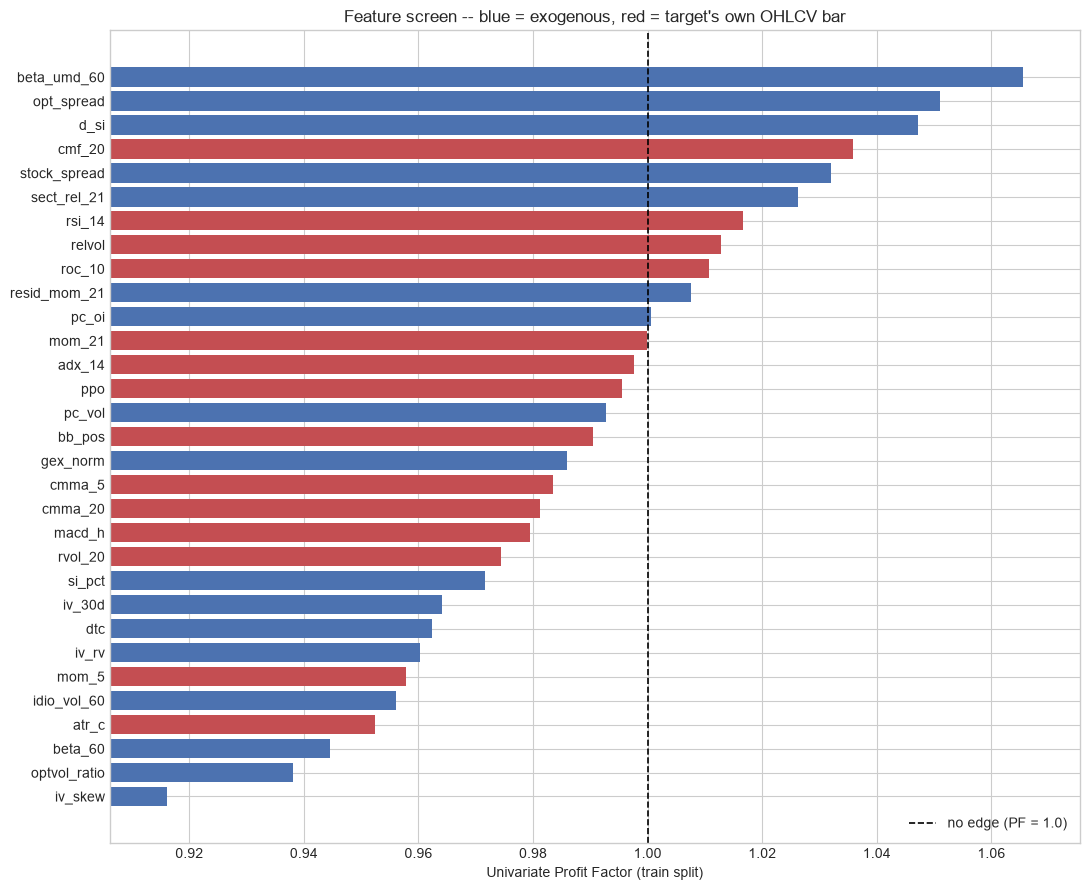

In [13]:
fig, ax = plt.subplots(figsize=(11, 9))
r = rank.sort_values("PF")
colors = ["#4C72B0" if b == "exogenous" else "#C44E52" for b in r["Bucket"]]
ax.barh(r["Feature"], r["PF"], color=colors)
ax.axvline(1.0, color="black", linestyle="--", lw=1.2, label="no edge (PF = 1.0)")
ax.set_xlabel("Univariate Profit Factor (train split)")
ax.set_title("Feature screen -- blue = exogenous, red = target's own OHLCV bar")
ax.legend(loc="lower right")
lo, hi = r["PF"].min(), r["PF"].max()
ax.set_xlim(lo - 0.01, hi + 0.01)
plt.tight_layout()
plt.show()

### Performing the drop

The brief asks to discard the worst 1 or 2. Two are dropped here.

One caveat is worth stating rather than hiding: the univariate Profit Factor
sees only a feature's **sign**, so a feature with a strong *negative* PF is not
useless — it is a working signal pointing the other way, which any of the models
downstream can flip. Short-term reversal (`mom_5`) is the textbook case. The
drop is therefore made on **distance from 1.0**, not on the raw value, so that
features carrying no information in either direction are the ones removed.

In [14]:
N_DROP = 2

rank["edge"] = (rank["PF"] - 1.0).abs()
drop_pool = rank.sort_values("edge")
dropped = drop_pool.head(N_DROP)["Feature"].tolist()

KEPT = [f for f in ALL_FEATURES if f not in dropped]   # market-wide survive: never ranked
SELECTED = [f"z_{f}" for f in KEPT] + CAL

print(f"Dropped (closest to PF = 1.0, i.e. no edge in either direction): {dropped}")
for f in dropped:
    row = rank[rank["Feature"] == f].iloc[0]
    print(f"   {f:14s} PF {row['PF']:.4f}  |edge| {row['edge']:.4f}  MI {row['MI']:.4f}")

kept_exog = [f for f in KEPT if f in EXOG]
n_tot, n_non_bar = len(KEPT) + len(CAL), len(kept_exog) + len(CAL)
print(f"\nSelected feature set: {len(SELECTED)} columns "
      f"({len(KEPT)} screened + {len(CAL)} calendar)")
print(f"  not based on the target's OHLCV bar: {n_non_bar}/{n_tot} = {n_non_bar / n_tot:.0%}")
assert n_non_bar / n_tot >= 0.5, "dropped below the brief's 50% exogenous requirement"
print("  [ok] still clears the brief's 50% requirement")

print(f"\nStrongest signals by |PF - 1| (sign shows the DIRECTION of the edge):")
for _, row in rank.sort_values("edge", ascending=False).head(6).iterrows():
    d = "long-high" if row["PF"] > 1 else "long-LOW (reversal)"
    print(f"   {row['Feature']:14s} PF {row['PF']:.4f}  t {row['T_stat']:+.2f}  -> {d}")

Dropped (closest to PF = 1.0, i.e. no edge in either direction): ['mom_21', 'pc_oi']
   mom_21         PF 0.9999  |edge| 0.0001  MI 0.0041
   pc_oi          PF 1.0005  |edge| 0.0005  MI 0.0104

Selected feature set: 38 columns (31 screened + 7 calendar)
  not based on the target's OHLCV bar: 25/38 = 66%
  [ok] still clears the brief's 50% requirement

Strongest signals by |PF - 1| (sign shows the DIRECTION of the edge):
   iv_skew        PF 0.9161  t -3.03  -> long-LOW (reversal)
   beta_umd_60    PF 1.0655  t +2.35  -> long-high
   optvol_ratio   PF 0.9381  t -2.28  -> long-LOW (reversal)
   beta_60        PF 0.9446  t -2.11  -> long-LOW (reversal)
   opt_spread     PF 1.0509  t +1.71  -> long-high
   atr_c          PF 0.9525  t -1.80  -> long-LOW (reversal)


## 10. Save the modelling-ready panel

Two files, both bundled with the submission so Part 2 also runs offline.

In [15]:
KEEP_COLS = (["date", "ticker", "permno", "sector", "target", "fwd_logret",
              "close_adj", "dlyprc", "vol_adj", "stock_spread"] + SELECTED)
KEEP_COLS = [c for c in dict.fromkeys(KEEP_COLS) if c in train.columns]

for name, d in [("model_train", train), ("model_test", test)]:
    out = d[KEEP_COLS].copy()
    p = f"{DATA}/{name}.csv"
    out.to_csv(p, index=False)
    print(f"  {name:12s} {len(out):>6,} rows x {len(out.columns)} cols "
          f"-> {p}  ({os.path.getsize(p) / 1e6:.1f} MB)")

pd.Series({"selected": SELECTED, "dropped": dropped, "bar": BAR,
           "exogenous": EXOG, "calendar": CAL,
           "sparse": SPARSE}).to_json(f"{DATA}/feature_meta.json")
print(f"  feature_meta.json -> {DATA}/feature_meta.json")

print("\n" + "=" * 68)
print("PART 1 COMPLETE")
print("=" * 68)
print(f"  panel      {PANEL_START:%Y-%m-%d} -> {PANEL_END:%Y-%m-%d}, {len(UNIVERSE)} names")
print(f"  train/test {len(train):,} / {len(test):,} rows, {EMBARGO_DAYS}-day embargo")
print(f"  features   {len(SELECTED)} selected, {n_non_bar / n_tot:.0%} not from the target's bar")
print(f"  next       Part 2 -- 5 models, grouped TimeSeriesSplit, rank-IC scorer")

  model_train  13,300 rows x 48 cols -> data/model_train.csv  (10.2 MB)
  model_test    4,960 rows x 48 cols -> data/model_test.csv  (3.8 MB)
  feature_meta.json -> data/feature_meta.json

PART 1 COMPLETE
  panel      2022-01-03 -> 2025-08-29, 20 names
  train/test 13,300 / 4,960 rows, 5-day embargo
  features   38 selected, 66% not from the target's bar
  next       Part 2 -- 5 models, grouped TimeSeriesSplit, rank-IC scorer
